## Combinatorial paths

A walk-forward gives one out-of-sample path, and one path is one draw. Combinatorial purged
validation cuts the bars into groups, tests every combination of a few of them with a search
on the rest, and recombines the tests into several paths, each a full run out of sample, so
a median and a spread replace a single number. The crossing of two averages on hourly
Bitcoin bars of 2024 and 2025.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 4.0.0, exchange-router 4.0.0


### The bars

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

data

Data(BTCUSDT, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)

### The splitter

Ten groups, two tested at a time: 45 splits, recombined into nine paths. A training piece
after a test span starts past the bar that span's last decision is scored on, and opens its
account after its warm-up, so no fit reads a test bar.

In [3]:
splitter = probatum.cv.CombinatorialPurged(groups=10, test_groups=2)

print(f"{splitter.get_n_splits()} splits")

45 splits


### The validation

Each split's search runs 30 random trials on its training bars, which lie on both sides of
its test span; its winner trades the test span, and each path is one run of the winners in
turn.

In [4]:
def crossing(data, fast, slow):
    up   = probatum.ta.ema(data.close, length=fast)
    down = probatum.ta.ema(data.close, length=slow)
    return numpy.where(up > down, 1.0, 0.0)


space = {"fast": probatum.Int(low=6, high=72),
         "slow": probatum.Int(low=96, high=528)}

study = probatum.validate(crossing, data=data, venue="binance_spot", cv=splitter,
                          space=space, search={"trials": 30, "sampler": "random"},
                          holdout=0.2, seed=7)

study.summary()

,value,low,high,level,method,why_none
paths,9,,,,,
score,1.62,0.07,3.17,0.95,"delta method, Newey-West lag 7, floored at lag zero",
windows,81,,,,,
windows_gained,56,,,,,
decay,0.50,,,,,
decay_error,0.37,,,,,
costs,"8,327",,,,,
price_pnl,"117,964",,,,,
holdout,,,,,,1
buy_and_hold,,,,,,1


### The paths

Each path's score, its statistics and what its account paid.

In [5]:
study.paths.to_pandas()[["number", "state", "score", "total_return_pct",
                         "max_drawdown_pct", "num_trades", "fees"]].round(decimals=2)

,number,state,score,total_return_pct,max_drawdown_pct,num_trades,fees
0,0,complete,1.62,121.91,25.60,25,848.57
1,1,complete,1.82,147.30,26.86,21,703.64
2,2,complete,1.29,88.30,32.27,30,910.27
3,3,complete,1.47,109.57,32.89,28,933.51
4,4,complete,1.72,134.68,27.67,23,745.83
5,5,complete,1.74,135.30,26.30,24,825.43
6,6,complete,1.40,98.45,34.13,34,956.64
7,7,complete,1.58,116.48,26.44,25,791.65
8,8,complete,1.79,144.36,23.76,23,786.94


### Their spread

Every path's equity, the median path's drawn bold.

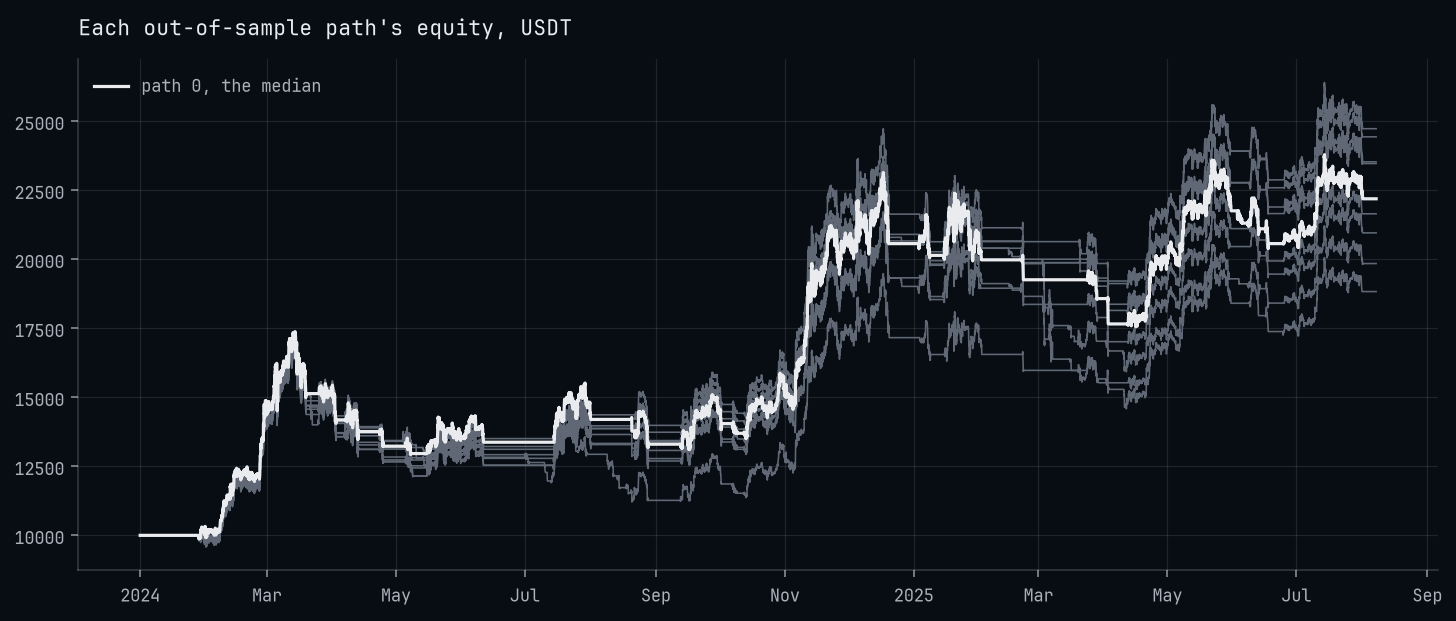

In [6]:
times  = pandas.to_datetime(data.time[:study.returns.shape[1]], utc=True)
equity = 10_000.0 * numpy.cumprod(1.0 + numpy.nan_to_num(study.returns), axis=1)
median = int(numpy.argsort(equity[:, -1])[len(equity) // 2])

figure, axes = matplotlib.pyplot.subplots()
for k, path in enumerate(equity):
    if k != median:
        axes.plot(times, path, color="C3", linestyle="-", linewidth=0.8)
axes.plot(times, equity[median], color="C0", linestyle="-", linewidth=1.6,
          label=f"path {median}, the median")
axes.set_title(label="Each out-of-sample path's equity, USDT")
axes.legend(loc="upper left")
matplotlib.pyplot.show()

### Each split's winner

Which lengths each split's search chose, on how many training bars.

In [7]:
study.fits.to_pandas()[["number", "test", "train", "fast", "slow", "fitted"]].head(
    n=10).round(decimals=2)

,number,test,train,fast,slow,fitted
0,0,0 to 2807,11226,61,353,1.76
1,1,"0 to 1403, 2808 to 4211",11225,31,469,1.37
2,2,"0 to 1403, 4212 to 5615",11225,19,501,1.21
3,3,"0 to 1403, 5616 to 7019",11225,41,407,1.13
4,4,"0 to 1403, 7020 to 8422",11226,29,462,0.47
5,5,"0 to 1403, 8423 to 9825",11226,32,432,1.72
6,6,"0 to 1403, 9826 to 11228",11226,31,474,1.34
7,7,"0 to 1403, 11229 to 12631",11226,29,518,1.03
8,8,"0 to 1403, 12632 to 14034",11227,29,515,1.27
9,9,1404 to 4211,11226,32,459,2.36
